This notebook is to understand how the climate varies in space and time, and which of that model can learn from the forcing.

### 1. Global-mean time series: how big is the climate-change signal?

In [3]:
import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

xr.set_options(use_bottleneck=False); # Accurate float32 reduction

DATADIR = Path("../data/lite")

In [4]:
# File handling
FILES = {
    "hist_1": "hist_train_1850_1931",
    "hist_2": "hist_train_1932_2014",
    "ssp126": "train_ssp126",
    "ssp370": "train_ssp370",
    "ssp585": "train_ssp585",
}

def open_file(key):
    """Open the ClimX file whose name ends with the suffix for `key`."""
    path = next(DATADIR.glob(f"*{FILES[key]}.nc"))
    return xr.open_dataset(path)

In [5]:
# Area weighted global mean
def global_mean(da):
    """Average over lat and lon, weighting each cell by
    cos(latitude)."""
    weights = np.cos(np.deg2rad(da.lat))
    return da.weighted(weights).mean(dim=("lat", "lon"))

In [6]:
with open_file("ssp126") as ds:
    tas = ds['tas'].isel(forcing_scenario=0)
    
    tas_global_daily = global_mean(tas).load()
tas_global_daily

<xarray.DataArray 'tas' (time: 31389)> Size: 251kB
array([285.70632627, 285.66914246, 285.62990071, ..., 286.38362134,
       286.38619424, 286.45820043])
Coordinates:
    forcing_scenario  <U6 24B 'ssp126'
  * time              (time) object 251kB 2015-01-01 12:00:00 ... 2100-12-30 ...

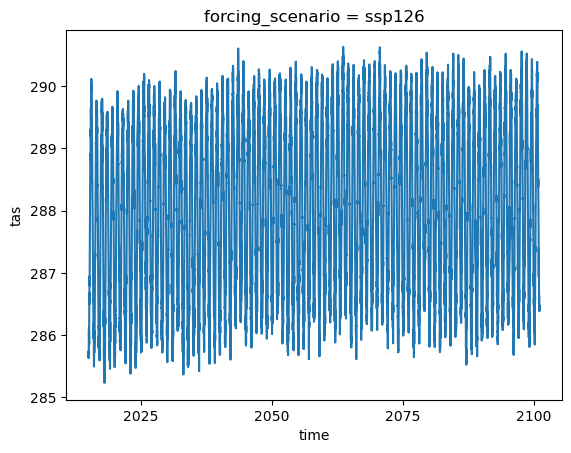

In [7]:
tas_global_daily.plot()
plt.show()

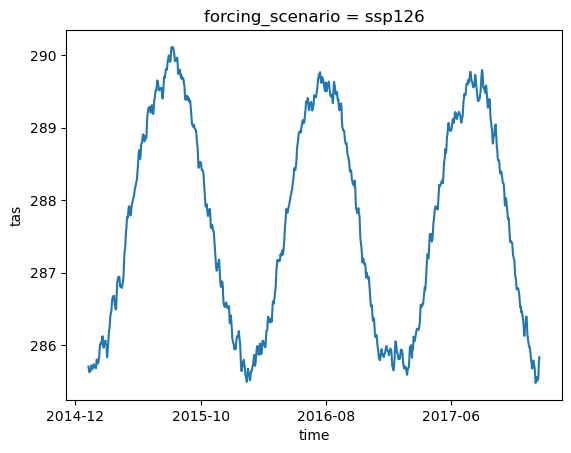

In [8]:
tas_global_daily.sel(time=slice("2015", "2017")).plot()
plt.show()

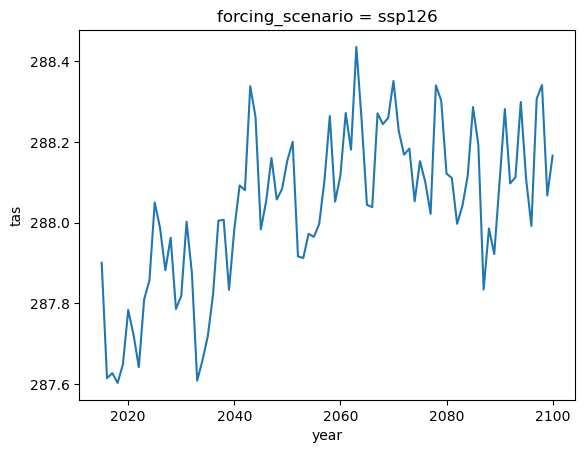

In [9]:
tas_global_daily.groupby("time.year").mean().plot()
plt.show()

In [10]:
def yearly_global_mean(key, var):
    """
    Yearly, area-weighted global mean of `var` for a scenario or
    'historical'.
    key (str): 'historical', 'ssp126', 'ssp370', 'ssp585'
    var (str): 'tas', 'tasmax', 'tasmin', 'pr', 'huss', 'psl', 'sfcWind'
    Example: yearly_global_mean("ssp126", "tas")
    """
    if key == "historical":
        keys = ["hist_1", "hist_2"]
    elif key in ["ssp126", "ssp370", "ssp585"]:
        keys = [key]
    else:
        raise ValueError(f"Unknown key {key}")
    parts = []
    for k in keys:
        with open_file(k) as ds:
            da = ds[var].isel(forcing_scenario=0)         # lazy, nothing read yet
            yearly = global_mean(da).groupby("time.year").mean().load()     # read + reduce
        parts.append(yearly)
    return xr.concat(parts, dim="year")

In [11]:
scenarios = ["historical", "ssp126", "ssp370", "ssp585"]

tas_yearly = {s: yearly_global_mean(s, "tas") - 273.15 for s in scenarios}   # °C
pr_yearly  = {s: yearly_global_mean(s, "pr") * 86400 for s in scenarios}     # mm/day (original data is in per second)

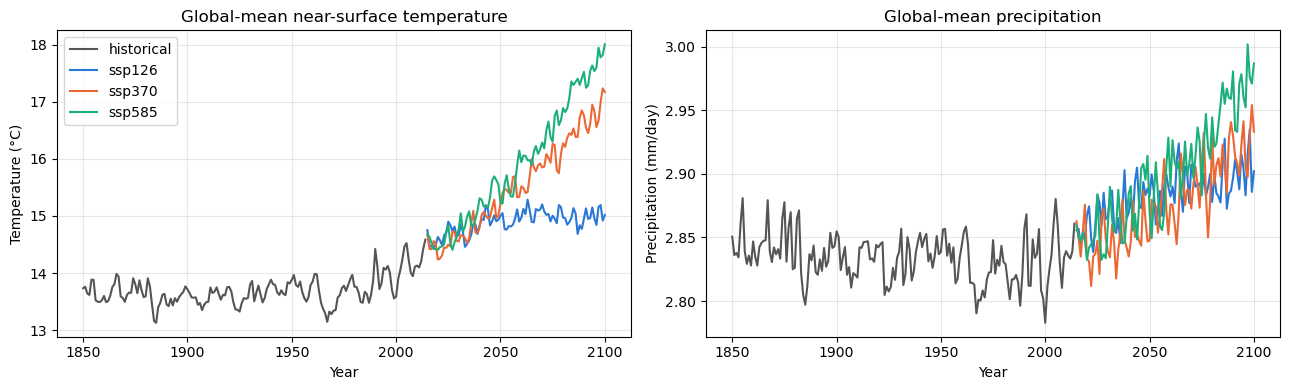

In [12]:
colors = {"historical": "#555555", "ssp126": "#2a78d6", "ssp370": "#eb6834", "ssp585": "#1baf7a"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for s in scenarios:
    axes[0].plot(tas_yearly[s].year, tas_yearly[s], color=colors[s], linewidth=1.5, label=s)
    axes[1].plot(pr_yearly[s].year, pr_yearly[s], color=colors[s], linewidth=1.5, label=s)

axes[0].set_title("Global-mean near-surface temperature")
axes[0].set_ylabel("Temperature (°C)")
axes[1].set_title("Global-mean precipitation")
axes[1].set_ylabel("Precipitation (mm/day)")
for ax in axes:
    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)
axes[0].legend()

plt.tight_layout()
plt.show()

In [13]:
# Pre-industrial baseline
baseline =tas_yearly['historical'].sel(year=slice(1850,1900)).mean()

for s in ["ssp126", "ssp370", "ssp585"]:
    warming = (tas_yearly[s].sel(year=slice(2081, 2100)).mean() - baseline).item()
    print(f"{s}: {warming:.2f} °C warmer in 2081–2100 than 1850–1900")

ssp126: 1.35 °C warmer in 2081–2100 than 1850–1900
ssp370: 3.03 °C warmer in 2081–2100 than 1850–1900
ssp585: 3.82 °C warmer in 2081–2100 than 1850–1900


### Shared helper: monthly climatology

In [14]:
def monthly_climatology(key, var, start, end):
    """
    Mean of each calender month over the years [start, end].

    Returns an array with dimension (month, lat, lon).
    """
    with open_file(key) as ds:
        da = ds[var].isel(forcing_scenario=0).sel(time=slice(start, end))
        clim = da.groupby("time.month").mean().load()
    return clim

In [35]:
# Seasonal cycle at different latitudes
clim_tas = monthly_climatology("ssp126", "tas", "2015", "2040") - 273.15
zonal_tas_mean = clim_tas.mean(dim="lon") # One sea

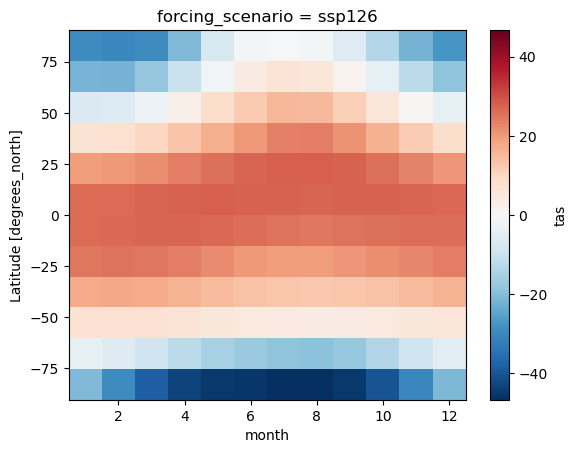

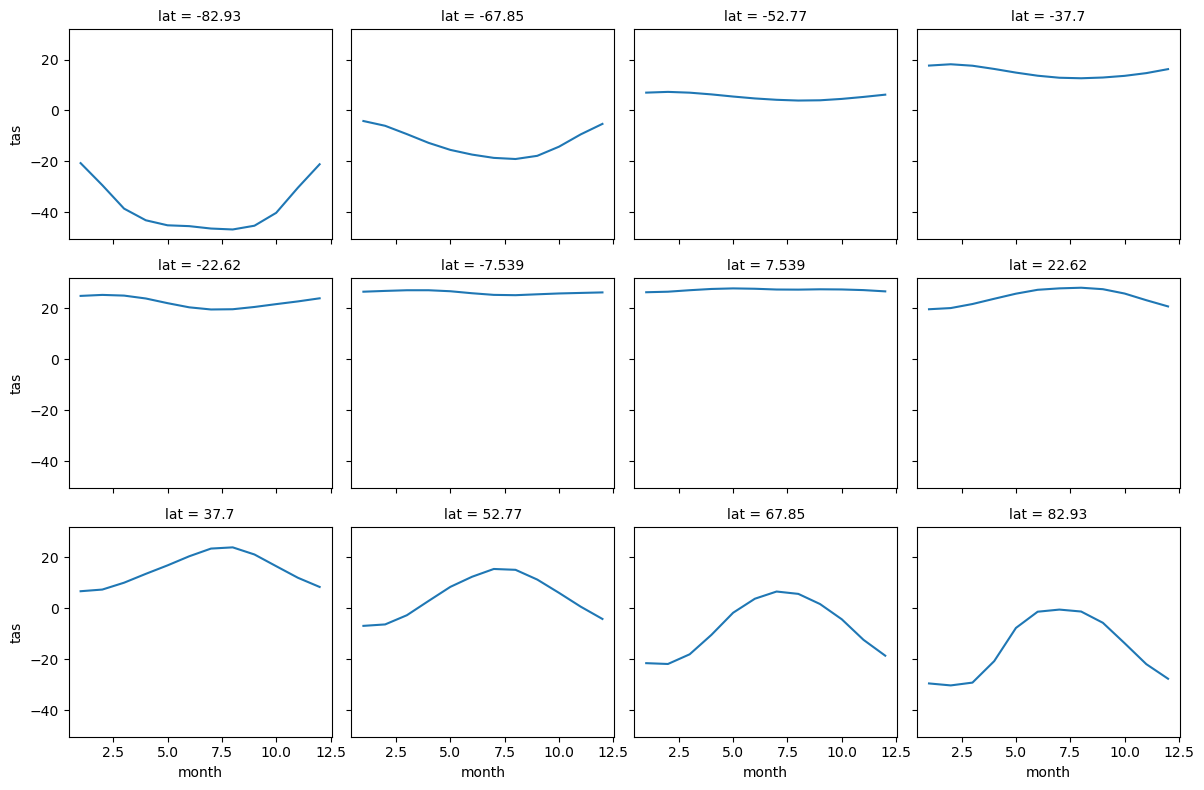

In [36]:
zonal_tas_mean.plot(x="month")
zonal_tas_mean.plot(x="month", col="lat", col_wrap=4, figsize=(12, 8), sharey=True)

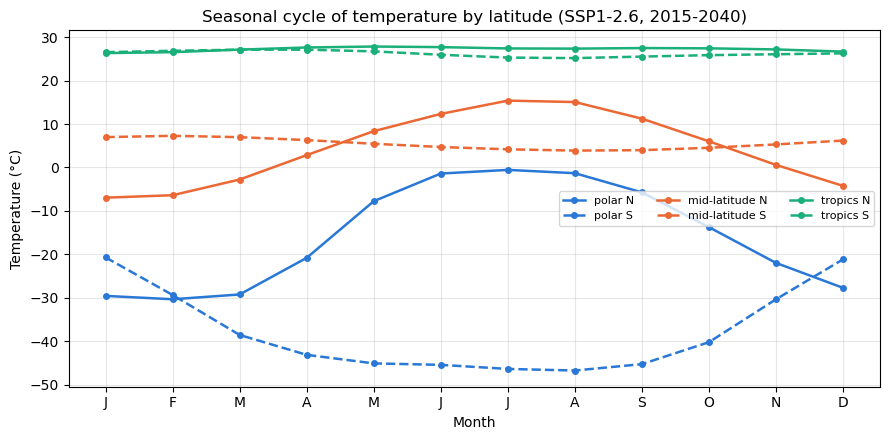

In [37]:
bands = {"polar": 82.93, "mid-latitude": 52.77, "tropics": 7.54}
band_colors = {"polar": "#2a78d6", "mid-latitude": "#eb6834", "tropics": "#1baf7a"}
month_labels = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

fig, ax = plt.subplots(figsize=(9, 4.5))
for band, lat in bands.items():
    for sign, hemi, style in [(1, "N", "-"), (-1, "S", "--")]:
        cycle = zonal_tas_mean.sel(lat=sign * lat, method="nearest")
        ax.plot(cycle.month, cycle, color=band_colors[band], linestyle=style,
                linewidth=1.8, marker='o', markersize=4, label=f"{band} {hemi}")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Seasonal cycle of temperature by latitude (SSP1-2.6, 2015-2040)")
ax.grid(alpha=0.3)
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

In [38]:
swing_by_lat = zonal_tas_mean.max(dim="month") - zonal_tas_mean.min(dim="month")
print(swing_by_lat.round(1).to_series())

lat
-82.931937    26.100000
-67.853403    14.900000
-52.774869     3.400000
-37.696335     5.500000
-22.617801     5.700000
-7.539267      1.900000
 7.539267      1.500000
 22.617801     8.400000
 37.696335    17.200001
 52.774869    22.299999
 67.853403    28.500000
 82.931937    29.799999
Name: tas, dtype: float32


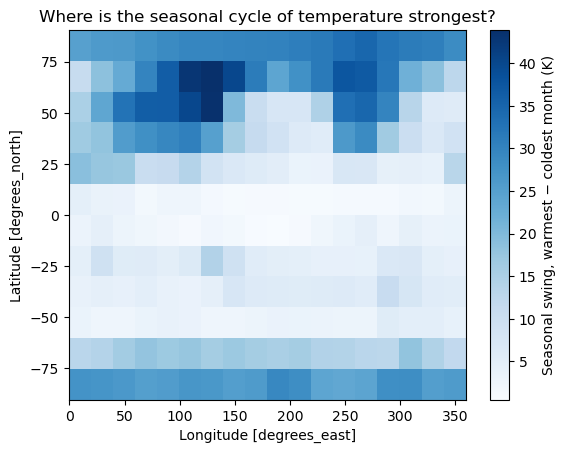

In [39]:
# 2b. Map of seasonal swing
swing_tas = clim_tas.max("month") - clim_tas.min("month")

swing_tas.plot(x="lon", y="lat", cmap="Blues",
                 cbar_kwargs={"label": "Seasonal swing, warmest − coldest month (K)"})
plt.title("Where is the seasonal cycle of temperature strongest?")
plt.show()

### 2c. Seasonal cycle of precipitation

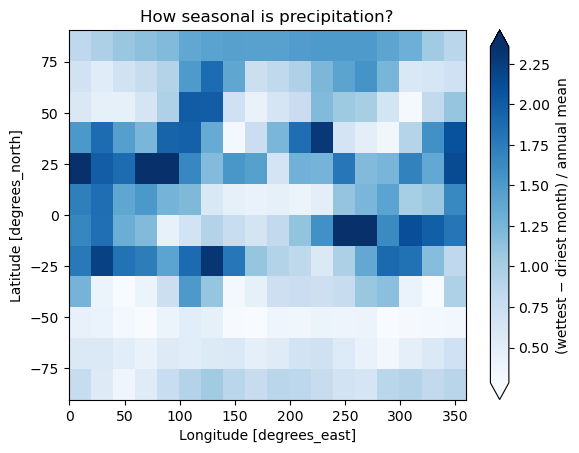

In [41]:
clim_pr = monthly_climatology("ssp126", "pr", "2015", "2040") * 86400 # mm/day
relative_swing_pr = (clim_pr.max("month") - clim_pr.min("month")) / clim_pr.mean("month")
relative_swing_pr.plot(x="lon", y="lat", cmap="Blues", robust=True,
                       cbar_kwargs={"label": "(wettest − driest month) / annual mean"})
plt.title("How seasonal is precipitation?")
plt.show()

### 2d. Does warming change the seasonal cycle?

In [48]:
early_tas = monthly_climatology("ssp585", "tas", "2015", "2034")
late_tas = monthly_climatology("ssp585", "tas", "2081", "2100")

warming_by_month = (late_tas - early_tas).mean("lon") # (month, lat)

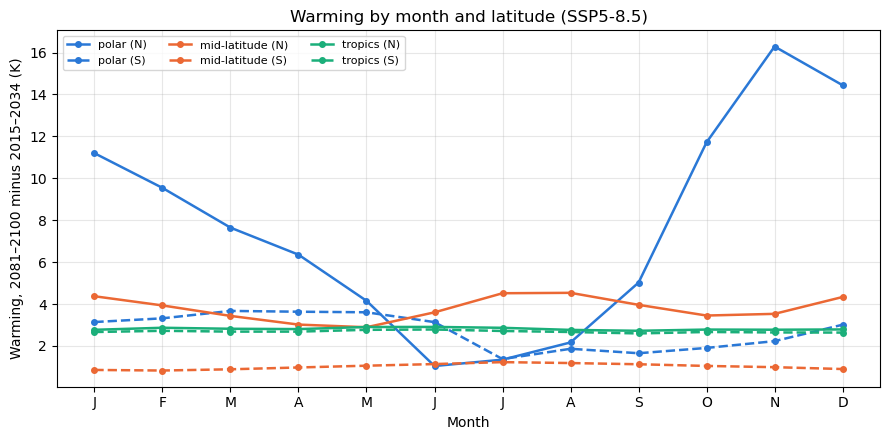

In [49]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for band, lat in bands.items():
    for sign, hemi, style in [(1, "N", "-"), (-1, "S", "--")]:
        w = warming_by_month.sel(lat=sign * lat, method="nearest")
        ax.plot(w.month, w, color=band_colors[band], linestyle=style,
                linewidth=1.8, marker="o", markersize=4, label=f"{band} ({hemi})")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_xlabel("Month")
ax.set_ylabel("Warming, 2081–2100 minus 2015–2034 (K)")
ax.set_title("Warming by month and latitude (SSP5-8.5)")
ax.grid(alpha=0.3)
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

Flat lines would mean warming only shifts the seasonal cycle. Bent line mean it changes the cycle's shape.

In [50]:
summary = xr.Dataset({
      "annual_mean_warming": warming_by_month.mean("month"),
      "max_month_warming": warming_by_month.max("month"),
      "min_month_warming": warming_by_month.min("month"),
  }).to_dataframe().round(2)
summary

,forcing_scenario,annual_mean_warming,max_month_warming,min_month_warming
lat,,,,
-82.931937,ssp585,2.71,3.670000,1.37
-67.853403,ssp585,1.50,2.170000,1.02
-52.774869,ssp585,1.02,1.230000,0.83
-37.696335,ssp585,1.81,1.960000,1.65
-22.617801,ssp585,2.39,2.570000,2.18
-7.539267,ssp585,2.69,2.780000,2.60
7.539267,ssp585,2.81,2.910000,2.72
22.617801,ssp585,3.12,3.310000,2.93
37.696335,ssp585,3.36,3.940000,2.88
